# 04 Wintervergleich der Begehungen

Teil 2: Begehungen und Wirkung

**Worum es geht**
- Frage: Sinkt der Rücklauf einer Station von der Heizperiode vor der Begehung zur Heizperiode danach?
- Die kurzen Fenster aus Notebook 02 (21 gegen 21 Tage) messen den Jahresgang mit. Zwei Heizperioden decken dieselben Kalendermonate ab, ohne Vorjahresversatz und ohne Sommer.
- Witterung über Heizgradstunden, Netzeinflüsse über eine Kontrollgruppe ohne Begehung (Diff-in-Diff).

**Daten**
- liest: Stundenreihen aus Notebook 00 über `src/nb00_daten.py`, Außentemperatur über `src/weather.py`, Begehungen über `src/load_begehungen.py`
- schreibt: `data/processed/wintervergleich_kernwinter.csv`, `data/processed/wintervergleich_erweitert.csv`
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/jahresvergleich.py`, Winterabgrenzung in `src/season.py`, Tests in `tests/test_jahresvergleich.py`

## 1 Setup

- Bibliotheken und Projektmodule laden.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import jahresvergleich as jv
from src import load_begehungen as lb
from src import nb00_daten as nb00
from src import season
from src import weather

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (9, 4)

### 1.1 Parameter

- `VARIANTE`: Winterabgrenzung der Hauptauswertung (Kernwinter Dezember bis Februar). `VARIANTE_SENS`: Gegenprobe September bis April mit Übergangsmonaten (Abschnitt 11). Beide aus `season.SEASON_MONTHS`.
- Drei Schwellen zu je 60 %: Tagesabdeckung (Anteil der Kalendertage mit Messwert), Stundenabdeckung (nur als strengere Gegenprobe) und verbleibender Anteil der Heizperiode.
- `KANDIDATEN_L`: Fensterlängen des früheren Jahresvergleichs für die Vorstufe in Abschnitt 3.

In [2]:
VARIANTE = jv.WINTER_KERN
VARIANTE_SENS = jv.WINTER_ERWEITERT

MIN_TAGESABDECKUNG = 0.6
MIN_COVERAGE = 0.6
MIN_FENSTERANTEIL = 0.6
RT_SCHWELLE = jv.RT_SCHWELLE

KANDIDATEN_L = [365, 330, 300, 270, 240, 210, 180, 120]
ALT_HAUPT_L = 270
ALT_ZWEIT_L = 180

for name, (m_start, m_end) in sorted(jv.WINTER_VARIANTEN.items()):
    print(f"{name:10s}: Monat {m_start:2d} bis Monat {m_end} des Folgejahres")
for seg in (season.KERNWINTER, season.UEBERGANG_FRUEH, season.UEBERGANG_SPAET):
    monate = sorted(m for m, s in season.SEASON_MONTHS.items() if s == seg)
    print(f"season.py {seg:16s}: Monate {monate}")

erweitert : Monat  9 bis Monat 4 des Folgejahres
kernwinter: Monat 12 bis Monat 2 des Folgejahres
season.py kernwinter      : Monate [1, 2, 12]
season.py uebergang_frueh : Monate [9, 10, 11]
season.py uebergang_spaet : Monate [3, 4]


## 2 Daten laden

- Stundenreihen aus Notebook 00 über `src/nb00_daten.py`. Fünf Zähler haben eine ODS-Nachlieferung bis Juli 2026, alle anderen enden am 11.07.2025.
- Bei den fünf fehlen ab Mai 2024 gemessene Energie- und Volumenstände. `lade_serien` integriert sie aus Leistung und Durchfluss.
- Dazu Außentemperatur, Heizgradstunden und die Begehungen.

In [3]:
serien = nb00.lade_serien()
ladefehler = nb00.nicht_aufbereitet()
historien = {z: (d.index[0].normalize(), d.index[-1].normalize())
             for z, d in serien.items() if len(d)}
hist_von = min(v[0] for v in historien.values())
hist_bis = max(v[1] for v in historien.values())

print(f"{len(serien)} Zaehlerreihen aus Notebook 00, "
      f"{len(ladefehler)} dort nicht aufbereitet")
if len(ladefehler):
    display(ladefehler)
print(f"Historie insgesamt: {hist_von.date()} .. {hist_bis.date()} "
      f"({(hist_bis - hist_von).days} Tage)")

93 Zaehlerreihen aus Notebook 00, 9 dort nicht aufbereitet


,meter,dateien,grund
0,41566330,"41566330_2025n.csv, 41566330__n.csv","von NB 00 übersprungen (siehe dort, Abschnitt 2)"
1,41566331,"41566331_2025n.csv, 41566331__n.csv","von NB 00 übersprungen (siehe dort, Abschnitt 2)"
2,41566332,"41566332_2025n.csv, 41566332__n.csv","von NB 00 übersprungen (siehe dort, Abschnitt 2)"
3,41628863,"41628863_2025n.csv, 41628863__n.csv","von NB 00 übersprungen (siehe dort, Abschnitt 2)"
4,41704231,"41704231_2025n.csv, 41704231__n.csv","von NB 00 übersprungen (siehe dort, Abschnitt 2)"
5,41704232,"41704232_2025n.csv, 41704232__n.csv","von NB 00 übersprungen (siehe dort, Abschnitt 2)"
6,48090145,"48090145_2025n.csv, 48090145__n.csv","von NB 00 übersprungen (siehe dort, Abschnitt 2)"
7,86792512,86792512_2025n.csv,"von NB 00 übersprungen (siehe dort, Abschnitt 2)"
8,721354800,721354800__n.csv,"von NB 00 übersprungen (siehe dort, Abschnitt 2)"


Historie insgesamt: 2021-11-01 .. 2026-07-20 (1722 Tage)


In [4]:
#Heizgradstunden bis über Juli 2026 hinaus
t_out = weather.load_outdoor_temperature(hist_von,
                                         pd.Timestamp("2026-08-01"),
                                         allow_download=False)
hdh = weather.heating_degree_hours(t_out)
print(f"Aussentemperatur: {len(t_out)} Stunden, "
      f"{int(t_out['interpolated'].sum())} davon interpoliert")
print(f"Heizgradstunden gesamt: {hdh.sum():,.0f} Kh "
      f"(Heizgrenze {15.0:.0f} °C)")

Aussentemperatur: 41612 Stunden, 7 davon interpoliert
Heizgradstunden gesamt: 238,579 Kh (Heizgrenze 15 °C)


In [5]:
begehungen = (lb.begehungen_mit_zaehler(available=set(serien))
                .dropna(subset=["meter", "datum"]))
begehungen["meter"] = begehungen["meter"].astype(int)
begehungen_je_meter = lb.begehung_dates_by_meter(available=set(serien))
zaehlerwechsel = lb.meter_changes()

print(f"{len(begehungen)} Begehungen mit Zaehlernummer und Datum, "
      f"{begehungen['meter'].nunique()} Zaehler")
print(f"Begehungszeitraum: {begehungen['datum'].min().date()} .. "
      f"{begehungen['datum'].max().date()}")
print(f"Zaehler mit mehr als einer Begehung: "
      f"{sum(len(v) > 1 for v in begehungen_je_meter.values())}")
display(begehungen["datum"].dt.to_period("M").value_counts().sort_index()
        .rename("begehungen").to_frame())

/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)
/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


58 Begehungen mit Zaehlernummer und Datum, 56 Zaehler
Begehungszeitraum: 2024-08-26 .. 2025-09-16
Zaehler mit mehr als einer Begehung: 2


,begehungen
datum,
2024-08,2
2024-09,34
2024-10,3
2024-11,13
2024-12,1
2025-03,1
2025-09,4


- 93 Zählerreihen aus Notebook 00. Nicht aufbereitet sind dort die 8 Zähler, die keine HAST sind, und die falsch benannte Datei `721354800__n.csv` (sie gehört zu 72135480). Historie 01.11.2021 bis 20.07.2026.
- 58 Begehungen mit Zählernummer und Datum an 56 Zählern, 26.08.2024 bis 16.09.2025; 34 davon im September 2024.

## 3 Vorstufe: warum nicht das volle Jahr

- Ein Vorjahresvergleich über ein langes Fenster ist an der Datenlage gescheitert.
- Gezählt wird je Fensterlänge, wie viele Begehungen davor und danach vollständige Daten haben.

In [6]:
uebersicht = []
for L in KANDIDATEN_L:
    a = jv.abdeckung(begehungen, historien, L)
    uebersicht.append({
        "fenster_tage": L,
        "begehungen_gesamt": len(a),
        "beide_fenster_vollstaendig": int(a["vollstaendig"].sum()),
        "zaehler": int(a.loc[a["vollstaendig"], "meter"].nunique()),
    })
display(pd.DataFrame(uebersicht))

machbar = jv.abdeckung(begehungen, historien, ALT_HAUPT_L)
print(f"maximal verfuegbare Tage nach einer Begehung: "
      f"{machbar['tage_danach'].max():.0f}")
print(f"Median Tage danach: {machbar['tage_danach'].median():.0f}, "
      f"Median Tage davor: {machbar['tage_davor'].median():.0f}")

,fenster_tage,begehungen_gesamt,beide_fenster_vollstaendig,zaehler
0,365,58,2,2
1,330,58,2,2
2,300,58,11,11
3,270,58,27,27
4,240,58,30,29
5,210,58,36,35
6,180,58,36,35
7,120,58,37,36


maximal verfuegbare Tage nach einer Begehung: 678
Median Tage danach: 295, Median Tage davor: 438


- Ein volles Jahr danach gibt es nur für 2 der 58 Begehungen, beide an Zählern mit Nachlieferung.
- Alle anderen Zähler enden am 11.07.2025. Die früheste Begehung war am 26.08.2024, danach bleiben also höchstens 319 Tage.
- Fallzahl je Fensterlänge: 330 Tage 2, 270 Tage 27, 180 Tage 36.
- 270 Tage mit Vorjahresversatz: 27 auswertbare Begehungen, aber der halbe Sommer liegt im Fenster.

## 4 Winterzuordnung und Fenster

- Anker ist immer der Kernwinter Dezember bis Februar, auch bei erweiterter Abgrenzung.
- Begehung zwischen zwei Kernwintern: Verglichen werden die beiden benachbarten (September 2024: 2023/24 gegen 2024/25).
- Begehung im Kernwinter: Dieser Winter fällt heraus, verglichen werden der davor und der danach.

In [7]:
zuordnung = pd.DataFrame([
    {"beispiel": t,
     **{k: v for k, v in jv.winterzuordnung(t).items()
        if k in ("winter_vor_label", "winter_nach_label", "angeschnitten")}}
    for t in ["2024-08-26", "2024-09-16", "2024-11-15", "2024-12-02",
              "2025-01-20", "2025-03-05", "2025-09-11"]
])
display(zuordnung)

beg_z = begehungen.assign(
    **pd.DataFrame([jv.winterzuordnung(d) for d in begehungen["datum"]],
                   index=begehungen.index)[
        ["winter_vor_label", "winter_nach_label", "angeschnitten"]])
print(f"{int(beg_z['angeschnitten'].sum())} von {len(beg_z)} Begehungen fallen "
      f"in einen Kernwinter und verlieren ihn als Vergleichsfenster")
display(beg_z.loc[beg_z["angeschnitten"],
                  ["meter", "datum", "winter_vor_label", "winter_nach_label"]]
        .assign(datum=lambda d: d["datum"].dt.date))
display(beg_z.groupby(["winter_vor_label", "winter_nach_label"])
        .size().rename("begehungen").to_frame())

,beispiel,winter_vor_label,winter_nach_label,angeschnitten
0,2024-08-26,2023/24,2024/25,False
1,2024-09-16,2023/24,2024/25,False
2,2024-11-15,2023/24,2024/25,False
3,2024-12-02,2023/24,2025/26,True
4,2025-01-20,2023/24,2025/26,True
5,2025-03-05,2024/25,2025/26,False
6,2025-09-11,2024/25,2025/26,False


1 von 58 Begehungen fallen in einen Kernwinter und verlieren ihn als Vergleichsfenster


,meter,datum,winter_vor_label,winter_nach_label
11,72135443,2024-12-02,2023/24,2025/26


begehungen
winter_vor_label winter_nach_label            
2023/24          2024/25                    52
                 2025/26                     1
2024/25          2025/26                     5

In [8]:
zeilen = []
for name in (VARIANTE, VARIANTE_SENS):
    for tag in ("2024-09-16", "2024-11-15", "2025-09-11"):
        f = jv.winterfenster(tag, name)
        mon_vor = sorted({d.month for d in pd.date_range(f["vor_start"],
                                                         f["vor_end"], freq="D")})
        mon_nach = sorted({d.month for d in pd.date_range(f["nach_start"],
                                                          f["nach_end"], freq="D")})
        zeilen.append({"variante": name, "begehung": tag,
                       "vor": f"{f['vor_start'].date()}..{f['vor_end'].date()}",
                       "nach": f"{f['nach_start'].date()}..{f['nach_end'].date()}",
                       "monate_gleich": mon_vor == mon_nach,
                       "fensteranteil": round(f["fensteranteil"], 3)})
display(pd.DataFrame(zeilen))

,variante,begehung,vor,nach,monate_gleich,fensteranteil
0,kernwinter,2024-09-16,2023-12-01..2024-02-29,2024-12-01..2025-02-28,True,1.000
1,kernwinter,2024-11-15,2023-12-01..2024-02-29,2024-12-01..2025-02-28,True,1.000
2,kernwinter,2025-09-11,2024-12-01..2025-02-28,2025-12-01..2026-02-28,True,1.000
3,erweitert,2024-09-16,2023-09-17..2024-04-30,2024-09-17..2025-04-30,True,0.934
4,erweitert,2024-11-15,2023-11-16..2024-04-30,2024-11-16..2025-04-30,True,0.686
5,erweitert,2025-09-11,2024-09-12..2025-04-30,2025-09-12..2026-04-30,True,0.955


- 1 von 58 Begehungen (Zähler 72135443, 02.12.2024) liegt in einem Kernwinter und verliert ihn als Vergleichsfenster. 52 Begehungen vergleichen 2023/24 mit 2024/25.
- `monate_gleich`: Beide Fenster decken dieselben Kalendermonate ab; in allen Beispielen erfüllt.
- `fensteranteil`: verbleibender Teil der Heizperiode, wenn die Begehung in ein Fenster ragt. Das gibt es nur bei erweiterter Abgrenzung; derselbe Ausschnitt fällt dann in beiden Fenstern weg. Unter `MIN_FENSTERANTEIL` fällt der Fall heraus.

## 5 Abdeckung und Ausschlussbilanz

- Abdeckungsschwelle als Parameter, jeder Ausschluss mit Grund in der Tabelle.
- Die Abdeckung bleibt auch für die ausgeschlossenen Fälle sichtbar.

In [9]:
def winter_auswertung(variante, serien_, historien_, begehungen_,
                      min_tagesabdeckung=MIN_TAGESABDECKUNG,
                      min_coverage=0.0):
    """Wintertabelle plus Ausschlussgrund je Zeile."""
    tab = jv.wintervergleich_tabelle(
        serien_, begehungen_, variante, hdh=hdh,
        meter_changes={z: [] for z in serien_},
        begehungen_je_meter=begehungen_je_meter,
    )
    a = jv.winter_abdeckung(begehungen_, historien_, variante)
    tab = tab.merge(a[["meter", "datum", "vollstaendig"]],
                    on=["meter", "datum"], how="left")
    return jv.winter_ausschlussbilanz(
        tab, min_tagesabdeckung=min_tagesabdeckung,
        min_coverage=min_coverage, min_fensteranteil=MIN_FENSTERANTEIL)


winter = winter_auswertung(VARIANTE, serien, historien, begehungen)
sub = winter[winter["auswertbar"]]

print(f"{len(begehungen)} Begehungen mit Zaehlernummer und Datum, "
      f"{len(winter)} davon mit ladbarer Zeitreihe")
display(winter["ausschlussgrund"].value_counts().rename("faelle").to_frame())
print(f"auswertbar: {len(sub)} Begehungen an {sub['meter'].nunique()} Zaehlern")
print(f"davon {int(sub['weitere_begehung'].sum())} mit einer weiteren Begehung "
      f"im Fenster")

58 Begehungen mit Zaehlernummer und Datum, 53 davon mit ladbarer Zeitreihe


,faelle
ausschlussgrund,
auswertbar,45
Historie deckt nicht beide Winter,7
Tagesabdeckung Nachher-Winter < 60%,1


auswertbar: 45 Begehungen an 44 Zaehlern
davon 0 mit einer weiteren Begehung im Fenster


In [10]:
anzeige = winter[["meter", "datum", "winter_vor_label", "winter_nach_label",
                  "tagesabdeckung_vor", "tagesabdeckung_nach",
                  "coverage_vor", "coverage_nach", "ausschlussgrund"]].copy()
anzeige["datum"] = anzeige["datum"].dt.date
display(anzeige.sort_values("ausschlussgrund").head(16).round(3))
print(f"... {len(anzeige)} Zeilen insgesamt")
print()
print("Tagesabdeckung gegen Stundenabdeckung, Median ueber die auswertbaren Faelle")
for seite in ("vor", "nach"):
    print(f"  {seite:4s}: Tage {sub[f'tagesabdeckung_{seite}'].median():.3f}, "
          f"Stunden {sub[f'coverage_{seite}'].median():.3f}")

,meter,datum,winter_vor_label,winter_nach_label,tagesabdeckung_vor,tagesabdeckung_nach,coverage_vor,coverage_nach,ausschlussgrund
0,68956367,2025-09-12,2024/25,2025/26,1.000,0.000,0.999,0.000,Historie deckt nicht beide Winter
7,80912191,2024-09-13,2023/24,2024/25,0.000,0.822,0.000,0.815,Historie deckt nicht beide Winter
9,72135486,2025-09-13,2024/25,2025/26,1.000,0.000,0.999,0.000,Historie deckt nicht beide Winter
10,72135443,2024-12-02,2023/24,2025/26,1.000,0.000,1.000,0.000,Historie deckt nicht beide Winter
11,80912165,2024-09-09,2023/24,2024/25,1.000,0.000,1.000,0.000,Historie deckt nicht beide Winter
23,81019433,2024-09-10,2023/24,2024/25,0.000,0.822,0.000,0.815,Historie deckt nicht beide Winter
24,68956373,2025-03-12,2024/25,2025/26,1.000,0.000,0.999,0.000,Historie deckt nicht beide Winter
45,72135441,2024-10-14,2023/24,2024/25,1.000,0.000,0.999,0.000,Tagesabdeckung Nachher-Winter < 60%
1,68956348,2024-09-09,2023/24,2024/25,1.000,1.000,1.000,0.999,auswertbar
2,68956353,2024-09-23,2023/24,2024/25,1.000,1.000,1.000,0.999,auswertbar


... 53 Zeilen insgesamt

Tagesabdeckung gegen Stundenabdeckung, Median ueber die auswertbaren Faelle
  vor : Tage 1.000, Stunden 1.000
  nach: Tage 1.000, Stunden 0.999


- 53 der 58 Begehungen haben eine ladbare Zeitreihe. Auswertbar sind 45 Begehungen an 44 Zählern. Ausgeschlossen: 7, weil die Historie nicht beide Winter deckt, und 1 wegen Tagesabdeckung im Nachher-Winter unter 60 %.
- Eine Zählergeneration liefert im älteren Teil der Exporte nur eine Zeile je Tag. Auf dem Stundenraster wirkt ein solcher Dezember wie rund 57 % abgedeckt, obwohl kein Tag fehlt.
- Geprüft wird deshalb die Tagesabdeckung; die Stundenabdeckung dient als Gegenprobe in Abschnitt 11.
- Nicht korrigiert: Wechselt das Raster im Fenster, gehen stündliche Abschnitte stärker in den Median ein.

## 6 Vorher/Nachher je Station

- Je Kennzahl die Differenz Winter danach minus Winter davor, über alle auswertbaren Begehungen.
- Dazu je Kennzahl ein gepaarter Wilcoxon-Test (prüft, ob die Differenzen im Median von null abweichen), auch dort, wo er nichts hergibt.

In [11]:
DIFFERENZEN = ["d_rt_median", "d_rt_mean_loaded", "d_dt_mean_loaded",
               "d_flow_median", "d_energie_kwh", "d_volumen_m3",
               "d_vollaststunden", "d_betrieb_anteil", "d_spitzenleistung_kw",
               "d_energie_je_kh", "d_volumen_je_kh"]


def verteilung(tab, spalten=DIFFERENZEN):
    """Gepaarter Wilcoxon je Kennzahl, auch dort wo er nichts hergibt."""
    teil = tab[tab["auswertbar"]] if "auswertbar" in tab.columns else tab
    zeilen = []
    for sp in spalten:
        w = teil[sp].dropna()
        zeile = {"kennzahl": sp, "n": len(w)}
        if len(w) >= 5 and w.abs().sum() > 0:
            zeile.update({"Q1": w.quantile(0.25), "Median": w.median(),
                          "Q3": w.quantile(0.75), "Mittel": w.mean(),
                          "wilcoxon_p": stats.wilcoxon(w)[1]})
        zeilen.append(zeile)
    return pd.DataFrame(zeilen)


print(f"Differenzen Winter danach minus Winter davor, Abgrenzung {VARIANTE}")
display(verteilung(winter).round(4))

Differenzen Winter danach minus Winter davor, Abgrenzung kernwinter


,kennzahl,n,Q1,Median,Q3,Mittel,wilcoxon_p
0,d_rt_median,45,-3.5500,-1.2000,1.5000,-2.1211,0.0906
1,d_rt_mean_loaded,44,-2.5808,-0.5819,1.0828,-1.4956,0.1151
2,d_dt_mean_loaded,44,-1.6843,0.1713,2.4142,1.0742,0.4140
3,d_flow_median,45,-3.0000,11.0000,31.0000,3.6889,0.0096
4,d_energie_kwh,45,59.0000,632.0000,1128.0000,245.1523,0.0022
5,d_volumen_m3,45,-37.1200,4.7700,54.6780,-17.8236,0.5310
6,d_vollaststunden,45,-101.1001,191.4657,503.8111,198.0852,0.0266
7,d_betrieb_anteil,45,-0.0256,0.0060,0.0379,0.0048,0.3289
8,d_spitzenleistung_kw,45,-3.1770,-0.3660,2.2410,-1.1302,0.2760
9,d_energie_je_kh,45,-0.0680,-0.0353,-0.0198,-0.0527,0.0000


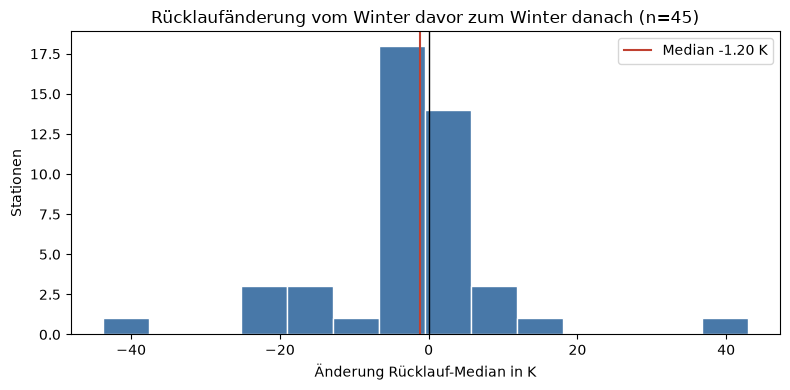

In [12]:
w = sub["d_rt_median"].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(w, bins=14, color="#4878a8", edgecolor="white")
ax.axvline(0, color="black", lw=1)
ax.axvline(w.median(), color="#c04030", lw=1.5,
           label=f"Median {w.median():+.2f} K")
ax.set_title(f"Rücklaufänderung vom Winter davor zum Winter danach (n={len(w)})")
ax.set_xlabel("Änderung Rücklauf-Median in K")
ax.set_ylabel("Stationen")
ax.legend()
fig.tight_layout()
plt.show()

- Rücklauf-Median sinkt im Median um 1,2 K (n = 45, Wilcoxon p = 0,091).
- Rohe Energie steigt (Median +632 kWh, p = 0,002), der Durchfluss-Median ebenso (+11 l/h, p = 0,010).
- Witterungsnormiert (`d_energie_je_kh`) sinkt die Energie (Median −0,0353 kWh/Kh). Abschnitt 7 zeigt den Grund: Der Nachher-Winter war kälter.

## 7 Heizgradstunden: gleiche Jahreszeit heißt nicht gleich kalt

- Heizgradstunden = Summe über alle Stunden, wie weit die Außentemperatur unter der Heizgrenze von 15 °C liegt. Ein Maß dafür, wie kalt ein Zeitraum war.
- Verglichen wird, wie kalt die beiden Winterfenster waren.

In [13]:
print(f"Heizgradstunden je Winterfenster, Median ueber {len(sub)} Stationen")
print(f"  Winter davor  : {sub['heizgradstunden_vor'].median():,.0f} Kh")
print(f"  Winter danach : {sub['heizgradstunden_nach'].median():,.0f} Kh")
schief = (sub["heizgradstunden_nach"].median()
          / sub["heizgradstunden_vor"].median() - 1)
print(f"  Schieflage    : {schief:+.1%}")
print()
print(f"  Energie roh       Median {sub['d_energie_kwh'].median():+,.0f} kWh")
print(f"  Energie normiert  Median {sub['d_energie_je_kh'].median():+.4f} kWh/Kh")
print()
#je Winterpaar, sonst verschwindet die Schieflage im Gesamtmedian
display(sub.groupby(["winter_vor_label", "winter_nach_label"])
        .agg(n=("meter", "size"),
             hgs_vor=("heizgradstunden_vor", "median"),
             hgs_nach=("heizgradstunden_nach", "median"))
        .assign(hgs_vor=lambda d: d["hgs_vor"].round(0),
                hgs_nach=lambda d: d["hgs_nach"].round(0),
                schieflage=lambda d: (d["hgs_nach"] / d["hgs_vor"] - 1).round(3)))

Heizgradstunden je Winterfenster, Median ueber 45 Stationen
  Winter davor  : 22,619 Kh
  Winter danach : 27,366 Kh
  Schieflage    : +21.0%

  Energie roh       Median +632 kWh
  Energie normiert  Median -0.0353 kWh/Kh



,,n,hgs_vor,hgs_nach,schieflage
winter_vor_label,winter_nach_label,,,,
2023/24,2024/25,43,22619.0,27366.0,0.210
2024/25,2025/26,2,27366.0,27174.0,-0.007


- Der Nachher-Winter war rund 21 % kälter (Median 27 366 gegen 22 619 Kh; im früheren Jahresvergleich 19,2 %). Rohe Energie ist damit unbrauchbar; `energie_je_kh` ist auf Heizgradstunden normiert.
- 43 der 45 Fälle liegen im Winterpaar 2023/24 gegen 2024/25. Die zwei übrigen (2024/25 gegen 2025/26) gibt es nur durch die Nachlieferung.
- Die Schieflage lässt sich nicht herausmitteln. Deshalb zählt die Kontrollgruppe (Abschnitt 10) mehr als der reine Vorher/Nachher-Test.

## 8 Vierfeldertafel

- Zustand je Winter: Rücklauf-Median über 50 °C = schlecht, sonst gut.
- Vier Zellen: gut zu gut, gut zu schlecht, schlecht zu gut, schlecht zu schlecht.

In [14]:
v = jv.vierfeldertafel(sub)
n_tafel = int(v.to_numpy().sum())
print(f"Abgrenzung {VARIANTE}, n={n_tafel}, "
      f"Schwelle {RT_SCHWELLE:.0f} °C Rücklauf-Median")
display(v)
display((v / n_tafel * 100).round(1))

Abgrenzung kernwinter, n=45, Schwelle 50 °C Rücklauf-Median


zustand_nach,gut,schlecht
zustand_vor,,
gut,27,4
schlecht,5,9


zustand_nach,gut,schlecht
zustand_vor,,
gut,60.0,8.9
schlecht,11.1,20.0


In [15]:
ohne_wirkung = sub[(sub["zustand_vor"] == "schlecht")
                   & (sub["zustand_nach"] == "schlecht")]
print(f"schlecht -> schlecht: {len(ohne_wirkung)} von {n_tafel} "
      f"({len(ohne_wirkung) / n_tafel * 100:.0f} %)")
display(ohne_wirkung[["meter", "datum", "kategorie", "rt_median_vor",
                      "rt_median_nach", "d_rt_median", "weitere_begehung"]]
        .assign(datum=lambda d: d["datum"].dt.date)
        .sort_values("rt_median_nach", ascending=False)
        .round(1))

schlecht -> schlecht: 9 von 45 (20 %)


,meter,datum,kategorie,rt_median_vor,rt_median_nach,d_rt_median,weitere_begehung
28,80912182,2024-09-19,mittlere,71.5,69.6,-1.9,False
35,68956356,2024-09-19,geringe,59.7,60.8,1.1,False
5,68956352,2024-09-18,mittlere,57.9,58.1,0.2,False
25,72135442,2024-09-12,mittlere,69.2,54.4,-14.8,False
40,68956344,2024-09-20,viele,54.8,53.7,-1.1,False
48,80912170,2024-11-19,mittlere,53.0,52.7,-0.3,False
43,80912178,2024-09-23,keine,54.1,51.8,-2.3,False
50,68956345,2024-09-18,mittlere,54.9,50.9,-4.0,False
39,68956372,2024-10-14,viele,71.9,50.3,-21.6,False


- n = 45: 27 gut zu gut (60,0 %), 4 gut zu schlecht (8,9 %), 5 schlecht zu gut (11,1 %), 9 schlecht zu schlecht (20,0 %).
- Die 9 Stationen, die vorher und nachher über 50 °C lagen, sind Kandidaten für eine erneute Prüfung. Zwei davon sanken deutlich (−14,8 K und −21,6 K), blieben aber über der Schwelle.
- Schwelle 50 °C auf den Rücklauf-Median wie in Notebook 02, im Dashboard (`RT_YELLOW_MAX`) und im Merkmal `rt_above_50_share_loaded`.

## 9 Aufschlüsselung nach Änderungskategorie

- Rücklaufänderung je dokumentierter Änderungskategorie (keine, geringe, mittlere, viele).

In [16]:
def nach_kategorie(tab, spalte="d_rt_median"):
    teil = tab[tab["auswertbar"]]
    zeilen = []
    for kat, g in teil.groupby("kategorie", dropna=False):
        wk = g[spalte].dropna()
        p = (stats.wilcoxon(wk)[1]
             if len(wk) >= 5 and wk.abs().sum() > 0 else np.nan)
        zeilen.append({"kategorie": kat, "n": len(wk),
                       "median_K": wk.median() if len(wk) else np.nan,
                       "wilcoxon_p": p})
    return pd.DataFrame(zeilen).sort_values("n", ascending=False)


print("Rücklaufänderung je dokumentierter Änderungskategorie")
display(nach_kategorie(winter).round(3))

Rücklaufänderung je dokumentierter Änderungskategorie


,kategorie,n,median_K,wilcoxon_p
2,mittlere,25,-1.10,0.545
3,viele,14,-2.35,0.064
0,geringe,4,0.90,NaN
1,keine,2,-2.00,NaN


- mittlere −1,10 K (n = 25, p = 0,545), viele −2,35 K (n = 14, p = 0,064); geringe und keine nur mit 4 bzw. 2 Fällen, ohne Test.
- Die Fallzahlen sind zu klein für eine Aussage, ob die Senkung mit dem Änderungsumfang wächst.

## 10 Kontrollgruppe und Diff-in-Diff

- Kontrollgruppe: Zähler ohne Begehung, gleiche Winterlogik mit demselben Datum, also dieselbe Witterung und Netzfahrweise.
- Diff-in-Diff = Änderung der begangenen Station minus Änderung der Kontrollgruppe.
- Keine Kausalaussage, weil die begangenen Stationen nicht zufällig ausgewählt wurden.

In [17]:
kontroll_serien = {z: d for z, d in serien.items()
                   if z not in set(begehungen["meter"])}
print(f"Kontrollgruppe: {len(kontroll_serien)} Zaehler ohne dokumentierte Begehung")

DID_SPALTEN = ("d_rt_median", "d_rt_mean_loaded", "d_energie_je_kh")


def diff_in_diff(tab, variante, spalten=DID_SPALTEN):
    """Je Begehung die Kontrollbewegung im selben Winterpaar abziehen.

    Die Kontrollgruppe wird ueber die Fenstergrenzen gecacht. Im
    Kernwinter teilen sich alle Begehungen eines Herbstes dieselben
    Grenzen, sonst liefe die Rechnung unnoetig lange.
    """
    teil = tab[tab["auswertbar"]]
    cache, zeilen = {}, []
    for _, r in teil.iterrows():
        f = jv.winterfenster(r["datum"], variante)
        key = (f["vor_start"], f["vor_end"], f["nach_start"], f["nach_end"])
        if key not in cache:
            k = jv.winter_kontrollgruppe(kontroll_serien, r["datum"],
                                         variante, hdh)
            k = jv.winter_ausschlussbilanz(
                k, min_tagesabdeckung=MIN_TAGESABDECKUNG,
                min_fensteranteil=MIN_FENSTERANTEIL)
            cache[key] = k[k["auswertbar"]]
        k = cache[key]
        if len(k) < 5:
            continue
        zeile = {"meter": r["meter"], "datum": r["datum"],
                 "kategorie": r["kategorie"], "n_kontrolle": len(k)}
        for sp in spalten:
            zeile[f"{sp}_station"] = r[sp]
            zeile[f"{sp}_kontrolle"] = k[sp].median()
            zeile[f"did_{sp}"] = r[sp] - k[sp].median()
        zeilen.append(zeile)
    return pd.DataFrame(zeilen)


did = diff_in_diff(winter, VARIANTE)
print(f"{len(did)} Begehungen mit auswertbarer Kontrollgruppe, im Median "
      f"{did['n_kontrolle'].median():.0f} Kontrollstationen je Winterpaar")

Kontrollgruppe: 42 Zaehler ohne dokumentierte Begehung


43 Begehungen mit auswertbarer Kontrollgruppe, im Median 34 Kontrollstationen je Winterpaar


In [18]:
for sp in DID_SPALTEN:
    wd = did[f"did_{sp}"].dropna()
    p = stats.wilcoxon(wd)[1] if len(wd) >= 5 and wd.abs().sum() > 0 else np.nan
    print(f"did_{sp:18s} n={len(wd):2d}  Median {wd.median():+.3f}  "
          f"Q1 {wd.quantile(.25):+.3f}  Q3 {wd.quantile(.75):+.3f}  "
          f"Wilcoxon p = {p:.4f}")

print()
print("Rohwerte zur Einordnung (Median):")
for sp in DID_SPALTEN:
    print(f"  {sp:18s} Station {did[f'{sp}_station'].median():+.3f}   "
          f"Kontrolle {did[f'{sp}_kontrolle'].median():+.3f}")

did_d_rt_median        n=43  Median -1.975  Q1 -4.150  Q3 +0.625  Wilcoxon p = 0.0076
did_d_rt_mean_loaded   n=43  Median -0.850  Q1 -2.660  Q3 +0.913  Wilcoxon p = 0.0564
did_d_energie_je_kh    n=43  Median -0.014  Q1 -0.046  Q3 +0.001  Wilcoxon p = 0.0051

Rohwerte zur Einordnung (Median):
  d_rt_median        Station -1.600   Kontrolle +0.375
  d_rt_mean_loaded   Station -0.771   Kontrolle +0.079
  d_energie_je_kh    Station -0.035   Kontrolle -0.021


In [19]:
display(did.groupby("kategorie")["did_d_rt_median"]
        .agg(n="size", median="median").round(2)
        .sort_values("n", ascending=False))

,n,median
kategorie,,
mittlere,24,-1.73
viele,13,-3.88
geringe,4,0.52
keine,2,-2.38


- 42 Kontrollzähler. 43 Begehungen haben eine auswertbare Kontrollgruppe, im Median 34 Kontrollstationen je Winterpaar.
- Kontrollgruppe im Median +0,4 K, begangene Stationen −1,6 K, Diff-in-Diff −2,0 K (n = 43, p ≈ 0,008). Das ist der belastbarste Teil der Auswertung.
- Je Kategorie: mittlere −1,73 K (n = 24), viele −3,88 K (n = 13); geringe und keine zu dünn besetzt.
- Wer vorher auffällig war, hat mehr Spielraum nach unten.

## 11 Sensitivität der Abgrenzung

- Zwei Gegenproben: erweiterte Abgrenzung September bis April und strenge Stundenabdeckung. Die strenge Variante wirft die Zähler mit Tagesraster heraus.

In [20]:
winter_sens = winter_auswertung(VARIANTE_SENS, serien, historien, begehungen)
winter_streng = winter_auswertung(VARIANTE, serien, historien, begehungen,
                                  min_coverage=MIN_COVERAGE)

zeilen = []
for name, tab in (("Kernwinter Dez-Feb", winter),
                  ("erweitert Sep-Apr", winter_sens),
                  (f"Kernwinter, Stunden >= {MIN_COVERAGE:.0%}", winter_streng)):
    teil = tab[tab["auswertbar"]]
    wk = teil["d_rt_median"].dropna()
    vt = jv.vierfeldertafel(teil)
    nt = int(vt.to_numpy().sum())
    zeilen.append({
        "abgrenzung": name, "n": len(wk),
        "median_d_rt_K": wk.median(),
        "wilcoxon_p": stats.wilcoxon(wk)[1] if len(wk) >= 5 else np.nan,
        "median_d_rt_mean_loaded_K": teil["d_rt_mean_loaded"].median(),
        "hgs_schieflage": (teil["heizgradstunden_nach"].median()
                           / teil["heizgradstunden_vor"].median() - 1),
        "schlecht_schlecht_%": vt.loc["schlecht", "schlecht"] / nt * 100 if nt else np.nan,
    })
display(pd.DataFrame(zeilen).round(4))

,abgrenzung,n,median_d_rt_K,wilcoxon_p,median_d_rt_mean_loaded_K,hgs_schieflage,schlecht_schlecht_%
0,Kernwinter Dez-Feb,45,-1.2,0.0906,-0.5819,0.2099,20.0000
1,erweitert Sep-Apr,35,-0.9,0.0703,-0.4185,0.1752,22.8571
2,"Kernwinter, Stunden >= 60%",45,-1.2,0.0906,-0.5819,0.2099,20.0000


- Das Ergebnis hängt kaum an der Abgrenzung: Kernwinter −1,2 K (p = 0,091), erweitert −0,9 K (n = 35, p = 0,070). Mit strenger Stundenabdeckung bleiben alle 45 Fälle drin, Ergebnis wie im Kernwinter.
- Anteil schlecht zu schlecht: 20,0 % im Kernwinter, 22,9 % in der erweiterten Abgrenzung.

## 12 Der alte und der neue Weg nebeneinander

- Der frühere kalendergleiche Jahresvergleich (270 und 180 Tage) wird mit denselben Kennzahlen neu gerechnet und gegenübergestellt.

In [21]:
def alt_auswertung(L):
    """Der bisherige kalendergleiche Jahresvergleich, unveraendert."""
    tab = jv.jahresvergleich_tabelle(
        serien, begehungen, L, modus=jv.MODUS_KALENDER, hdh=hdh,
        meter_changes={z: [] for z in serien},
        begehungen_je_meter=begehungen_je_meter,
    )
    a = jv.abdeckung(begehungen, historien, L, modus=jv.MODUS_KALENDER)
    tab = tab.merge(a[["meter", "datum", "vollstaendig"]],
                    on=["meter", "datum"], how="left")
    tab["auswertbar"] = (tab["vollstaendig"]
                         & (tab["coverage_vor"] >= MIN_COVERAGE)
                         & (tab["coverage_nach"] >= MIN_COVERAGE))
    return tab


def alt_diff_in_diff(tab, L, spalten=DID_SPALTEN):
    teil = tab[tab["auswertbar"]]
    cache, zeilen = {}, []
    for _, r in teil.iterrows():
        key = pd.Timestamp(r["datum"])
        if key not in cache:
            k = jv.kontrollgruppe_tabelle(kontroll_serien, r["datum"], L, hdh=hdh)
            cache[key] = k[(k["coverage_vor"] >= MIN_COVERAGE)
                           & (k["coverage_nach"] >= MIN_COVERAGE)]
        k = cache[key]
        if len(k) < 5:
            continue
        zeile = {"meter": r["meter"], "n_kontrolle": len(k)}
        for sp in spalten:
            zeile[f"{sp}_station"] = r[sp]
            zeile[f"{sp}_kontrolle"] = k[sp].median()
            zeile[f"did_{sp}"] = r[sp] - k[sp].median()
        zeilen.append(zeile)
    return pd.DataFrame(zeilen)


alt_haupt = alt_auswertung(ALT_HAUPT_L)
alt_zweit = alt_auswertung(ALT_ZWEIT_L)
alt_did = alt_diff_in_diff(alt_haupt, ALT_HAUPT_L)
print(f"Jahresvergleich {ALT_HAUPT_L} Tage: "
      f"{int(alt_haupt['vollstaendig'].sum())} vollstaendig, "
      f"{int(alt_haupt['auswertbar'].sum())} auswertbar")
print(f"Jahresvergleich {ALT_ZWEIT_L} Tage: "
      f"{int(alt_zweit['vollstaendig'].sum())} vollstaendig, "
      f"{int(alt_zweit['auswertbar'].sum())} auswertbar")

Jahresvergleich 270 Tage: 27 vollstaendig, 27 auswertbar
Jahresvergleich 180 Tage: 36 vollstaendig, 35 auswertbar


In [22]:
def kennwerte(name, tab, did_tab):
    teil = tab[tab["auswertbar"]]
    wk = teil["d_rt_median"].dropna()
    zeile = {"variante": name, "n": len(wk),
             "median_d_rt_K": wk.median(),
             "wilcoxon_p": stats.wilcoxon(wk)[1] if len(wk) >= 5 else np.nan,
             "hgs_schieflage": (teil["heizgradstunden_nach"].median()
                                / teil["heizgradstunden_vor"].median() - 1)}
    if did_tab is not None and len(did_tab):
        wd = did_tab["did_d_rt_median"].dropna()
        zeile.update({"n_did": len(wd), "did_median_K": wd.median(),
                      "did_p": stats.wilcoxon(wd)[1] if len(wd) >= 5 else np.nan,
                      "kontrolle_d_rt_K": did_tab["d_rt_median_kontrolle"].median()})
    return zeile


vergleich = pd.DataFrame([
    kennwerte(f"alt: Jahr {ALT_HAUPT_L} Tage kalendergleich", alt_haupt, alt_did),
    kennwerte(f"alt: Jahr {ALT_ZWEIT_L} Tage kalendergleich", alt_zweit, None),
    kennwerte(f"neu: Winter {VARIANTE}", winter, did),
])
display(vergleich.round(4))

,variante,n,median_d_rt_K,wilcoxon_p,hgs_schieflage,n_did,did_median_K,did_p,kontrolle_d_rt_K
0,alt: Jahr 270 Tage kalendergleich,27,-1.7,0.0395,0.1920,25.0,-1.500,0.0160,-0.400
1,alt: Jahr 180 Tage kalendergleich,35,-1.1,0.1067,0.1972,NaN,NaN,NaN,NaN
2,neu: Winter kernwinter,45,-1.2,0.0906,0.2099,43.0,-1.975,0.0076,0.375


- Bestätigt den bisherigen Befund: Fallzahl 45 statt 27, Diff-in-Diff −2,0 statt −1,5 K.
- Median −1,2 statt −1,7 K, gepaarter p-Wert 0,091 statt 0,040: mehr Fälle, etwas kleinerer Effekt, mehr Streuung.

## 13 Markierte Sonderfälle

- Begehungen mit einer weiteren Begehung im Fenster oder mit Zählerwechsel werden markiert und zur Gegenprobe weggelassen.

In [23]:
sonder = sub[sub["weitere_begehung"] | sub["meter_change"]]
print(f"{len(sonder)} von {len(sub)} auswertbaren Begehungen sind markiert")
if len(sonder):
    display(sonder[["meter", "datum", "kategorie", "weitere_begehung",
                    "meter_change", "d_rt_median", "d_energie_je_kh"]]
            .assign(datum=lambda d: d["datum"].dt.date).round(3))

ohne = sub[~(sub["weitere_begehung"] | sub["meter_change"])]
wo = ohne["d_rt_median"].dropna()
print(f"\nohne die markierten Faelle: n={len(wo)}, Median {wo.median():+.2f} K, "
      f"Wilcoxon p = {stats.wilcoxon(wo)[1]:.4f}")

0 von 45 auswertbaren Begehungen sind markiert

ohne die markierten Faelle: n=45, Median -1.20 K, Wilcoxon p = 0.0906


- 0 von 45 Begehungen sind markiert. Das Ergebnis bleibt bei −1,2 K (p = 0,091).

## 14 Ergebnistabelle sichern

- Schreibt beide Abgrenzungen (Kernwinter, erweitert) nach `data/processed/`.
- Nur Zählernummern, keine Adressen; `data/processed/` ist zusätzlich gitignored.

In [24]:
ziel = Path("..") / "data" / "processed"
ziel.mkdir(parents=True, exist_ok=True)

spalten = (["meter", "datum", "variante", "winter_vor_label",
            "winter_nach_label", "angeschnitten", "fensteranteil", "kategorie",
            "tagesabdeckung_vor", "tagesabdeckung_nach",
            "coverage_vor", "coverage_nach", "vollstaendig",
            "ausschlussgrund", "auswertbar", "weitere_begehung", "meter_change"]
           + [f"{k}_{s}" for k in jv.KENNZAHLEN for s in ("vor", "nach")]
           + [f"d_{k}" for k in jv.KENNZAHLEN]
           + ["zustand_vor", "zustand_nach"])

for name, tab in (("kernwinter", winter), ("erweitert", winter_sens)):
    pfad = ziel / f"wintervergleich_{name}.csv"
    tab[[c for c in spalten if c in tab.columns]].to_csv(pfad, index=False)
    print(f"{pfad.name}: {len(tab)} Zeilen")

wintervergleich_kernwinter.csv: 53 Zeilen
wintervergleich_erweitert.csv: 53 Zeilen


## 15 Gegenprobe ohne Nachlieferung

- Dieselbe Auswertung, aber die fünf Nachlieferungszähler werden am gemeinsamen Exportende 11.07.2025 abgeschnitten.

In [25]:
ODS_METER = nb00.lange_reihen(serien)
ende_gemeinsam = max(d.index[-1] for z, d in serien.items()
                     if z not in ODS_METER)
print(f"Zaehler mit Nachlieferung: {ODS_METER}")
print(f"gemeinsames Exportende der uebrigen: {ende_gemeinsam.date()}")

serien_kurz = dict(serien)
historien_kurz = dict(historien)
for zid in ODS_METER:
    d = serien[zid]
    serien_kurz[zid] = d[d.index <= ende_gemeinsam]
    historien_kurz[zid] = (d.index[0].normalize(),
                           serien_kurz[zid].index[-1].normalize())
    print(f"{zid}: {historien[zid][0].date()}..{historien[zid][1].date()}, "
          f"integrierte Zaehlerstaende: "
          f"{d.attrs['zaehlerstand_integriert']} Stunden")


Zaehler mit Nachlieferung: [68956347, 68956371, 68956372, 72167783, 80912172]
gemeinsames Exportende der uebrigen: 2025-07-11
68956347: 2021-11-01..2026-07-20, integrierte Zaehlerstaende: 8971 Stunden
68956371: 2021-11-01..2026-07-20, integrierte Zaehlerstaende: 8973 Stunden
68956372: 2021-11-01..2026-07-20, integrierte Zaehlerstaende: 8960 Stunden
72167783: 2021-11-01..2026-07-20, integrierte Zaehlerstaende: 8972 Stunden
80912172: 2023-09-08..2026-07-20, integrierte Zaehlerstaende: 8971 Stunden


In [26]:
winter_kurz = winter_auswertung(VARIANTE, serien_kurz, historien_kurz,
                                begehungen)
sub_kurz = winter_kurz[winter_kurz["auswertbar"]]

paare_kurz = set(zip(sub_kurz["meter"], sub_kurz["datum"]))
nur_voll = {(m, d) for m, d in zip(sub["meter"], sub["datum"])
            if (m, d) not in paare_kurz}
print(f"auswertbar mit Nachlieferung (oben): {len(sub)}")
print(f"auswertbar ohne Nachlieferung      : {len(sub_kurz)}")
print(f"nur mit Nachlieferung rechenbar    : {len(nur_voll)}")

if nur_voll:
    neu_tab = sub[[(m, d) in nur_voll
                   for m, d in zip(sub["meter"], sub["datum"])]]
    display(neu_tab[["meter", "datum", "winter_vor_label", "winter_nach_label",
                     "rt_median_vor", "rt_median_nach", "d_rt_median",
                     "d_dt_mean_loaded", "d_energie_je_kh"]]
            .assign(datum=lambda d: d["datum"].dt.date).round(2))

wk = sub_kurz["d_rt_median"].dropna()
print(f"\nmit Nachlieferung : n={len(w)}, Median {w.median():+.2f} K, "
      f"Wilcoxon p = {stats.wilcoxon(w)[1]:.4f}")
print(f"ohne Nachlieferung: n={len(wk)}, Median {wk.median():+.2f} K, "
      f"Wilcoxon p = {stats.wilcoxon(wk)[1]:.4f}")


auswertbar mit Nachlieferung (oben): 45
auswertbar ohne Nachlieferung      : 43
nur mit Nachlieferung rechenbar    : 2


,meter,datum,winter_vor_label,winter_nach_label,rt_median_vor,rt_median_nach,d_rt_median,d_dt_mean_loaded,d_energie_je_kh
6,68956371,2025-09-16,2024/25,2025/26,30.3,34.25,3.95,-4.1,0.01
13,72167783,2025-09-11,2024/25,2025/26,27.1,70.00,42.90,NaN,-0.55



mit Nachlieferung : n=45, Median -1.20 K, Wilcoxon p = 0.0906
ohne Nachlieferung: n=43, Median -1.60 K, Wilcoxon p = 0.0273


- Die Nachlieferung bringt zwei zusätzliche Fälle (68956371 und 72167783, Begehung September 2025), beide mit steigendem Rücklauf (+4,0 K und +42,9 K).
- 72167783 nimmt im Winter 2025/26 praktisch keine Wärme ab, der Rücklauf liegt auf Vorlaufniveau (Median 70 °C). Das passt zu einem Betriebszustand, nicht zu einer Maßnahmenwirkung.
- Mit Nachlieferung n = 45, −1,2 K, p ≈ 0,09; ohne n = 43, −1,6 K, p ≈ 0,03. Die zwei Nachlieferungsfälle drücken den Effekt.

## Zusammenfassung & Bewertung

**Ergebnis**
- 45 Begehungen an 44 Zählern auswertbar (Tagesabdeckung unter 60 % ausgeschlossen).
- Rücklauf-Median sinkt um 1,2 K (p ≈ 0,09), ohne Nachlieferung um 1,6 K (p ≈ 0,03).
- Diff-in-Diff gegen 42 Zähler ohne Begehung: −2,0 K (p ≈ 0,008).
- Vorher und nachher „schlecht“ (Schwelle 50 °C): 9 von 45, Kandidaten für eine erneute Prüfung.

**Belastbar**
- Der Rückgang bleibt nach Abzug der Kontrollgruppe. Das ist konsistent mit einer Wirkung der Begehungen.
- Kaum abhängig von der Winterabgrenzung (−0,9 bis −1,2 K).
- Auch die witterungsnormierte Energie sinkt gegenüber der Kontrollgruppe (−0,014 kWh/Kh, p ≈ 0,005).

**Schwach**
- Fast alle Fälle liegen in einem Winterpaar mit 21 % kälterem Nachher-Winter.
- Die Änderungskategorien sind zu dünn besetzt.
- Die Kontrollgruppe ist nicht zufällig, deshalb nur „konsistent mit“.

**Offen**
- Winter 2025/26 fehlt für 88 der 93 Zähler.